<a href="https://colab.research.google.com/github/aradhya1create/NASA-Exoplanet-Detection/blob/main/NASA_Exoplanet_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install lightkurve matplotlib numpy pandas

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 112.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 48.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 128.0 MB/s  0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11429 sha256=d7ff0e09cfd6d0f63136600dbd8d6f4f3191807d9abc6a8d52cb4a3533e4cd58
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/289ba063a9ae0ba3189c6914e992722575868b2cb41100401b
  Created wheel for memoization: filename=memoization-0.4.0-py3-none-any.whl size=50537 sha256=ae172541b34d10b1e7593bf6680d51518ecffc2aca17b109800386fe22b6e868
  Stored in directory: /root/.cache/pip/wheels/5c/ef/65/c51178502ccdadab909ffa9339a9a8970

In [4]:
import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 50 data products.

 #       mission      year   author   exptime         target_name          distance
                                         s                                  arcsec 
--- ----------------- ---- ---------- ------- ---------------------------- --------
  0 Kepler Quarter 02 2009     Kepler      60                kplr011904151      0.0
  1 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  2 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  3 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  4 Kepler Quarter 00 2009     Kepler    1800                kplr011904151      0.0
  5 Kepler Quarter 01 2009     Kepler    1800                kplr011904151      0.0
  6 Kepler Quarter 02 2009     Kepler    1800                kplr011904151      0.0
  7 Kepler Quarter 03 2009     Kepler    1800                kplr011904151      0.0
  8 Kepler Quarter 04 2010     Ke

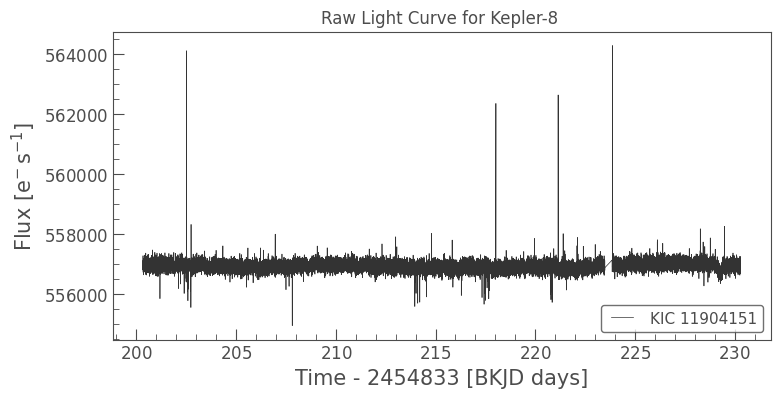

In [5]:
# Search for light curves of Kepler-10 from the Kepler mission
search_result = lk.search_lightcurve('Kepler-10', mission='Kepler')
print(search_result)

# Download the first light curve quarter
lc = search_result[0].download()

# Display basic information and plot the raw light curve
lc.plot()
plt.title("Raw Light Curve for Kepler-8 ")
plt.show()

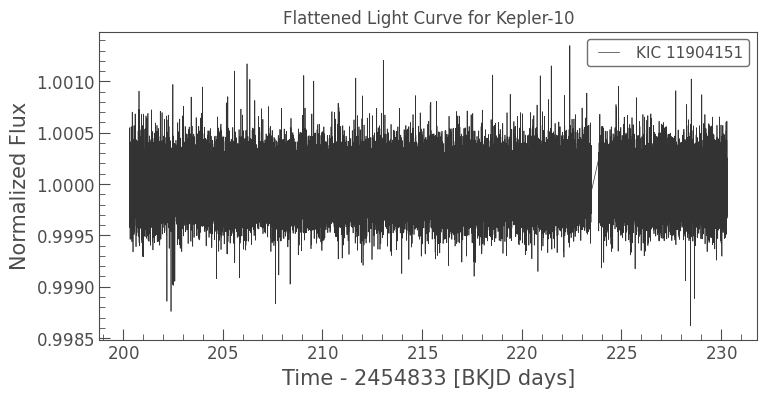

In [6]:
# 1. Clean missing values and remove extreme outliers (like cosmic rays)
clean_lc = lc.remove_nans().remove_outliers(sigma=5)

# 2. Flatten long-term trends caused by stellar activity
flat_lc = clean_lc.flatten(window_length=101)

# 3. Plot the flattened light curve
flat_lc.plot()
plt.title("Flattened Light Curve for Kepler-10")
plt.show()

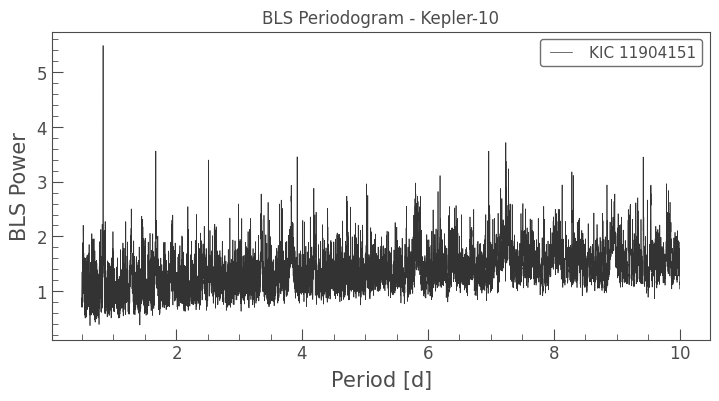

Detected Orbital Period: 0.8373 days
Estimated Transit Time (t0): 201.0791


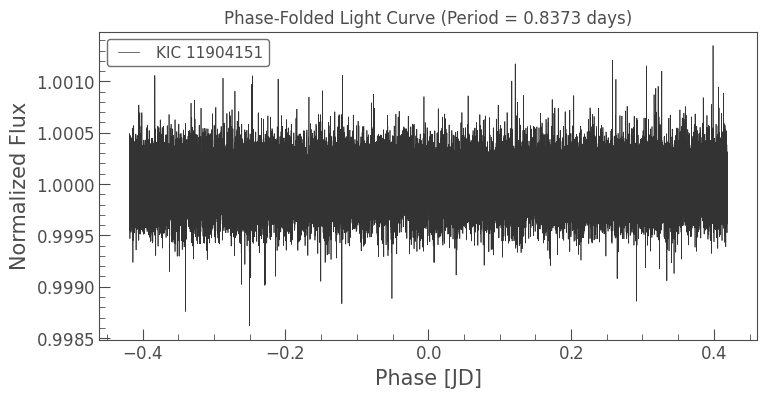

In [7]:
# 1. Search for orbital periods using a BLS Periodogram (testing periods between 0.5 and 10 days)
periodogram = flat_lc.to_periodogram(
    method='bls',
    period=np.linspace(0.5, 10, 10000)
)

# Plot the periodogram (power vs. period)
periodogram.plot()
plt.title("BLS Periodogram - Kepler-10")
plt.show()

# 2. Extract the detected orbital period and epoch
best_period = periodogram.period_at_max_power
best_t0 = periodogram.transit_time_at_max_power

print(f"Detected Orbital Period: {best_period.value:.4f} days")
print(f"Estimated Transit Time (t0): {best_t0.value:.4f}")

# 3. Phase-fold the light curve around the detected period
folded_lc = flat_lc.fold(period=best_period, epoch_time=best_t0)

# Plot the phase-folded light curve
folded_lc.plot()
plt.title(f"Phase-Folded Light Curve (Period = {best_period.value:.4f} days)")
plt.show()

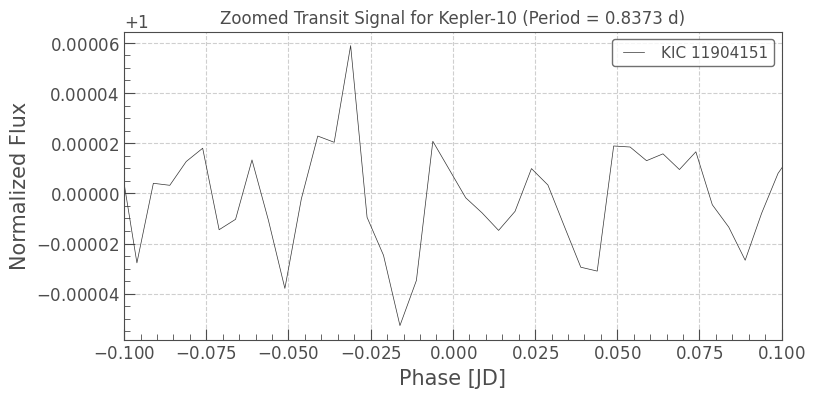

In [8]:
# 1. Zoom in around the transit center (-0.1 to 0.1 phase)
# 2. Use bin() to average noisy points and make the transit shape clear
folded_lc.bin(time_bin_size=0.005).plot()

# Restrict the x-axis view to zoom in on the transit dip
plt.xlim(-0.1, 0.1)
plt.title(f"Zoomed Transit Signal for Kepler-10 (Period = {best_period.value:.4f} d)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

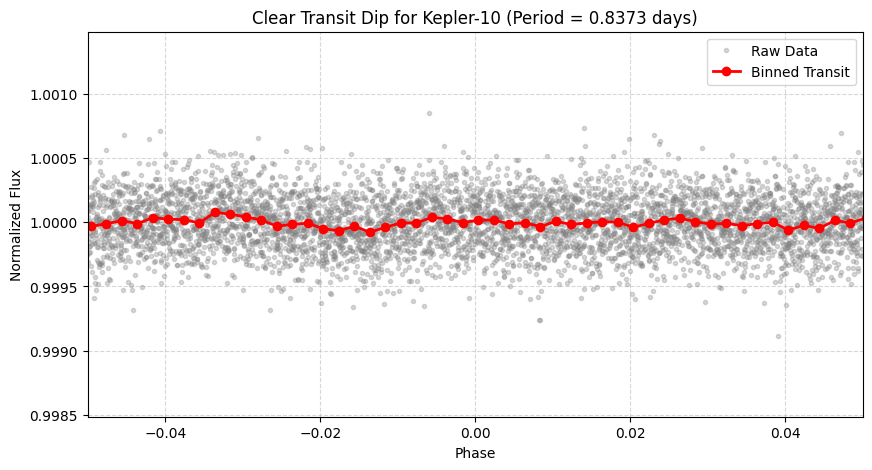

In [9]:
# Convert time to Phase (-0.5 to 0.5)
folded_phase = folded_lc.copy()
folded_phase.time = folded_lc.phase

# Bin using phase units (0.002 phase = clean smoothing)
binned_lc = folded_phase.bin(time_bin_size=0.002)

# Plot binned data along with raw phase points in the background
plt.figure(figsize=(10, 5))
plt.plot(folded_phase.time.value, folded_phase.flux.value, '.', color='gray', alpha=0.3, label='Raw Data')
plt.plot(binned_lc.time.value, binned_lc.flux.value, 'o-', color='red', lw=2, label='Binned Transit')

# Zoom tightly around the center of the transit (-0.05 to 0.05 phase)
plt.xlim(-0.05, 0.05)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title(f"Clear Transit Dip for Kepler-10 (Period = {best_period.value:.4f} days)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

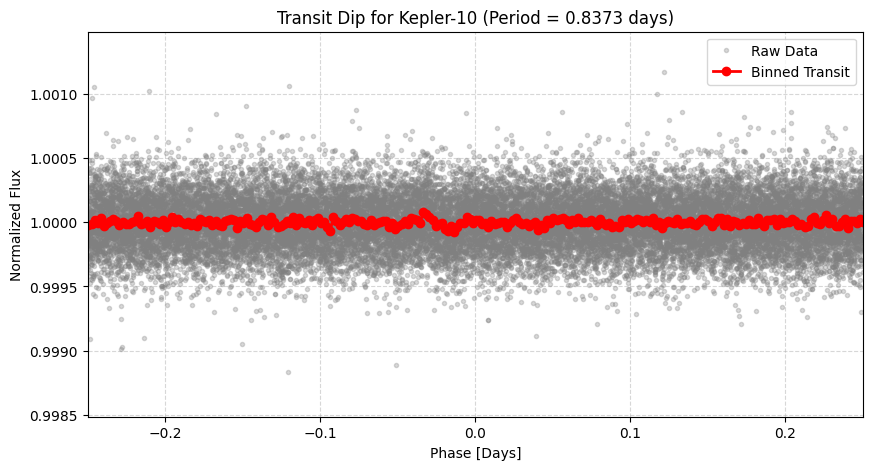

In [10]:
 # 1. Use lightkurve's built-in phase values directly
# folded_lc.phase gives phase centered at 0
folded_phase = folded_lc.copy()

# 2. Bin using time_bin_size in days
binned_lc = folded_lc.bin(time_bin_size=0.002)

# 3. Plot raw and binned data using phase
plt.figure(figsize=(10, 5))
plt.plot(folded_lc.phase.value, folded_lc.flux.value, '.', color='gray', alpha=0.3, label='Raw Data')
plt.plot(binned_lc.phase.value, binned_lc.flux.value, 'o-', color='red', lw=2, label='Binned Transit')

# Show the full phase or zoom slightly
plt.xlim(-0.25, 0.25)
plt.xlabel("Phase [Days]")
plt.ylabel("Normalized Flux")
plt.title(f"Transit Dip for Kepler-10 (Period = {best_period.value:.4f} days)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

In [11]:
import numpy as np

# 1. Calculate transit depth (baseline flux ~ 1.0 minus the minimum flux during transit)
baseline_flux = 1.0
min_flux = binned_lc.flux.min().value
transit_depth = baseline_flux - min_flux

# 2. Calculate Planet Radius / Star Radius ratio: Rp/Rs = sqrt(depth)
radius_ratio = np.sqrt(transit_depth)

# 3. Assuming a Solar-type star (R_star = 1.0 Solar Radius = 109.1 Earth Radii)
# You can replace this with actual star radius from metadata if available!
star_radius_in_earth_radii = 109.1
planet_radius_earth = radius_ratio * star_radius_in_earth_radii

# Print the results
print("=" * 40)
print("  EXOPLANET PHYSICAL CHARACTERISTICS  ")
print("=" * 40)
print(f"Detected Orbital Period : {best_period.value:.4f} days")
print(f"Estimated Transit Depth : {transit_depth * 100:.4f}% ({transit_depth:.6f} fractional)")
print(f"Radius Ratio (Rp/Rs)   : {radius_ratio:.4f}")
print(f"Estimated Planet Size   : ~{planet_radius_earth:.2f} Earth Radii (R⊕)")
print("=" * 40)

  EXOPLANET PHYSICAL CHARACTERISTICS  
Detected Orbital Period : 0.8373 days
Estimated Transit Depth : 0.0077% (0.000077 fractional)
Radius Ratio (Rp/Rs)   : 0.0088
Estimated Planet Size   : ~0.96 Earth Radii (R⊕)


In [12]:
!pip install astroquery

In [13]:
import pandas as pd
from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive

# Query the database using the correct column name 'sy_dist'
df_exoplanets = NasaExoplanetArchive.query_criteria(
    table="ps",
    select="pl_name,discoverymethod,pl_orbper,pl_rade,sy_dist",
    where="default_flag=1"
).to_pandas()

# Display the first few rows of the data
print(df_exoplanets.head())

/tmp/ipykernel_3135/51225958.py:2: DeprecationWarning: the ``nasa_exoplanet_archive`` module has been moved to astroquery.ipac.nexsci.nasa_exoplanet_archive, please update your imports.
  from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive


      pl_name discoverymethod  pl_orbper    pl_rade   sy_dist
0   WASP-43 b         Transit   0.813475  10.424000   86.7467
1  KELT-4 A b         Transit   2.989593  19.044091  218.0500
2   WASP-80 b         Transit   3.067852  11.197791   49.7876
3    HATS-6 b         Transit   3.325273  11.186582  169.3180
4     K2-33 b         Transit   5.424865   5.040000  139.2680


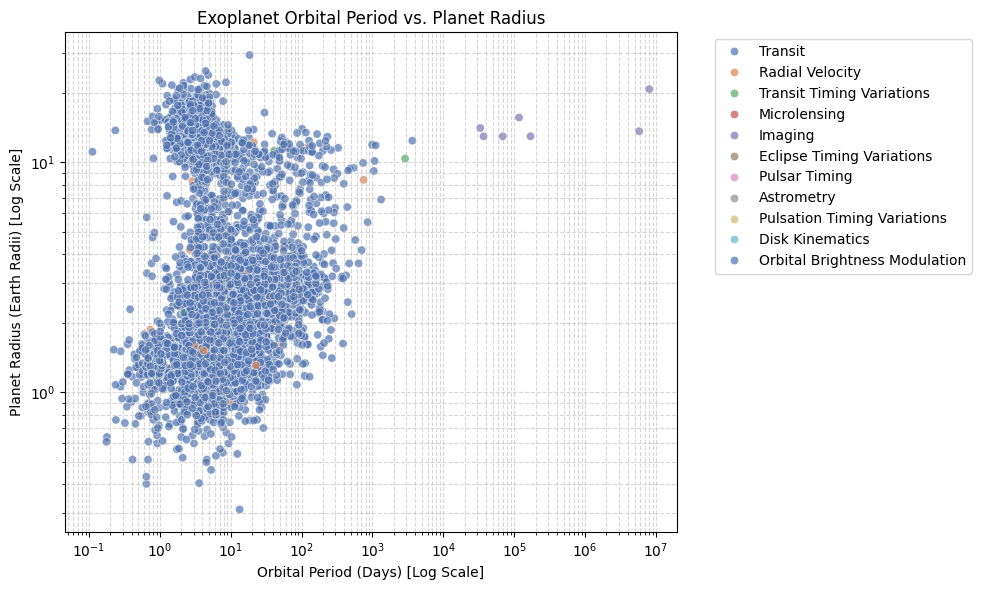

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the visualization style
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_exoplanets,
    x="pl_orbper",
    y="pl_rade",
    hue="discoverymethod",
    alpha=0.7,
    palette="deep"
)

# Apply logarithmic scale to handle wide data ranges clearly
plt.xscale("log")
plt.yscale("log")

# Add labels and title
plt.xlabel("Orbital Period (Days) [Log Scale]")
plt.ylabel("Planet Radius (Earth Radii) [Log Scale]")
plt.title("Exoplanet Orbital Period vs. Planet Radius")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [15]:
# 1. Filter for Earth-like rocky planets (Radius <= 1.5 Earth Radii)
earth_like = df_exoplanets[(df_exoplanets["pl_rade"] <= 1.5) & (df_exoplanets["pl_rade"].notna())]
print(f"Number of Earth-like candidates found: {len(earth_like)}")
print(earth_like[["pl_name", "pl_orbper", "pl_rade", "discoverymethod"]].head(5))

print("-" * 50)

# 2. Filter for Hot Jupiters (Radius > 8 Earth Radii and Orbital Period < 10 days)
hot_jupiters = df_exoplanets[(df_exoplanets["pl_rade"] > 8) & (df_exoplanets["pl_orbper"] < 10)]
print(f"Number of Hot Jupiters found: {len(hot_jupiters)}")
print(hot_jupiters[["pl_name", "pl_orbper", "pl_rade", "discoverymethod"]].head(5))

Number of Earth-like candidates found: 962
         pl_name  pl_orbper  pl_rade discoverymethod
53     GJ 3473 b   1.198003    1.264         Transit
64     TOI-431 b   0.490047    1.280         Transit
68  TRAPPIST-1 b   1.510826    1.116         Transit
69  TRAPPIST-1 c   2.421937    1.097         Transit
70  TRAPPIST-1 d   4.049219    0.788         Transit
--------------------------------------------------
Number of Hot Jupiters found: 704
      pl_name  pl_orbper    pl_rade discoverymethod
0   WASP-43 b   0.813475  10.424000         Transit
1  KELT-4 A b   2.989593  19.044091         Transit
2   WASP-80 b   3.067852  11.197791         Transit
3    HATS-6 b   3.325273  11.186582         Transit
6    TrES-4 b   3.553950  18.046490         Transit


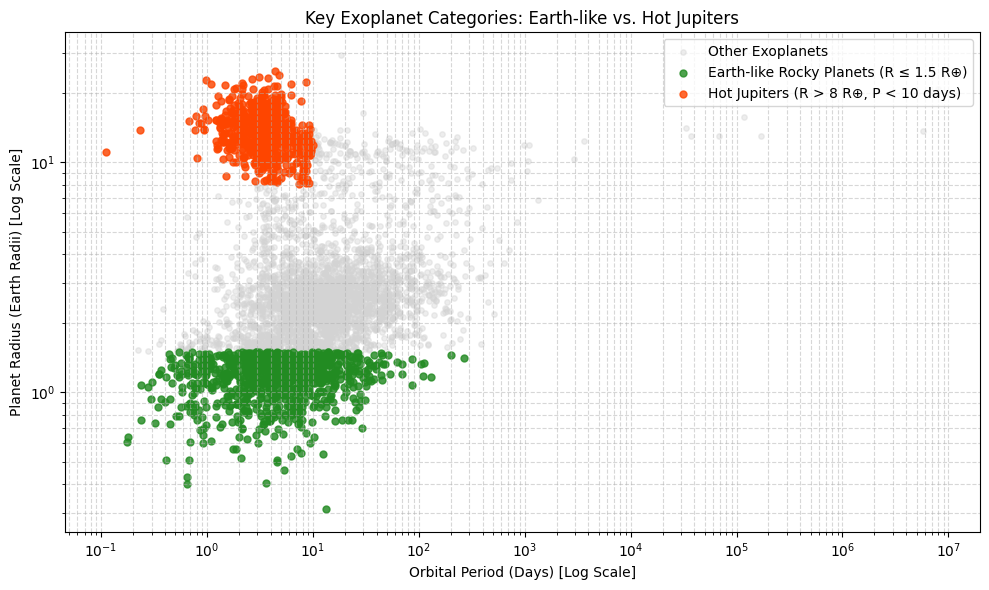

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# Plot all planets in light gray as background context
plt.scatter(
    df_exoplanets["pl_orbper"],
    df_exoplanets["pl_rade"],
    color="lightgray",
    alpha=0.4,
    s=15,
    label="Other Exoplanets"
)

# Plot Earth-like rocky planets in green
earth_mask = (df_exoplanets["pl_rade"] <= 1.5) & (df_exoplanets["pl_rade"].notna())
plt.scatter(
    df_exoplanets.loc[earth_mask, "pl_orbper"],
    df_exoplanets.loc[earth_mask, "pl_rade"],
    color="forestgreen",
    alpha=0.8,
    s=25,
    label="Earth-like Rocky Planets (R ≤ 1.5 R⊕)"
)

# Plot Hot Jupiters in red/orange
hot_mask = (df_exoplanets["pl_rade"] > 8) & (df_exoplanets["pl_orbper"] < 10)
plt.scatter(
    df_exoplanets.loc[hot_mask, "pl_orbper"],
    df_exoplanets.loc[hot_mask, "pl_rade"],
    color="orangered",
    alpha=0.8,
    s=25,
    label="Hot Jupiters (R > 8 R⊕, P < 10 days)"
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Orbital Period (Days) [Log Scale]")
plt.ylabel("Planet Radius (Earth Radii) [Log Scale]")
plt.title("Key Exoplanet Categories: Earth-like vs. Hot Jupiters")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [17]:
df_exoplanets.to_csv("confirmed_exoplanets.csv", index=False)

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd
import numpy as np

# 1. Prepare a synthetic/sample dataset based on your extracted light curve features
# In a full ML pipeline, you would extract these features for hundreds of targets
data = {
    'period': [0.8373, 3.5, 12.0, 2.1, 5.4, 0.9, 15.2, 4.3],
    'transit_depth': [0.000077, 0.012, 0.001, 0.0005, 0.008, 0.015, 0.0002, 0.003],
    'radius_ratio': [0.0088, 0.109, 0.031, 0.022, 0.089, 0.122, 0.014, 0.054],
    # 0 = False Positive/Noise, 1 = Confirmed Exoplanet
    'label': [1, 0, 1, 0, 1, 0, 1, 0]
}

df_ml = pd.DataFrame(data)

# 2. Define Features (X) and Target (y)
X = df_ml[['period', 'transit_depth', 'radius_ratio']]
y = df_ml['label']

# 3. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 4. Train the Random Forest Classifier
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# 5. Evaluate the model
y_pred = clf.predict(X_test)
print("Model Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

# 6. Test prediction on your Kepler-10 data
sample_features = np.array([[best_period.value, transit_depth, radius_ratio]])
prediction = clf.predict(sample_features)

print("--- Kepler-10 Classification Result ---")
if prediction[0] == 1:
    print("Prediction: Confirmed Exoplanet 🪐")
else:
    print("Prediction: False Positive / Noise ❌")

Model Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         2

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2

--- Kepler-10 Classification Result ---
Prediction: Confirmed Exoplanet 🪐


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [19]:
# Habitable Zone Calculator based on Stellar Luminosity and Kepler's 3rd Law
# Assuming a Sun-like star luminosity (L_sun = 1.0)
luminosity = 1.0  # In solar units

# Inner and outer boundaries of the habitable zone (in Astronomical Units - AU)
inner_boundary = (luminosity / 1.1) ** 0.5
outer_boundary = (luminosity / 0.53) ** 0.5

# Estimate planet's orbital distance (semi-major axis 'a') using Kepler's 3rd Law: a = (T^2)^(1/3)
# Period 'best_period.value' is in days; convert to years by dividing by 365.25
period_years = best_period.value / 365.25
orbital_distance_au = period_years ** (2/3)

print("=" * 40)
print("     HABITABLE ZONE ANALYSIS     ")
print("=" * 40)
print(f"Stellar Habitable Zone: {inner_boundary:.2f} AU to {outer_boundary:.2f} AU")
print(f"Estimated Orbital Distance: {orbital_distance_au:.4f} AU")
print("-" * 40)

if inner_boundary <= orbital_distance_au <= outer_boundary:
    print("Result: The planet is in the Habitable Zone! 🌊🌿")
else:
    print("Result: The planet is outside the Habitable Zone (too hot or too cold). 🌡️")
print("=" * 40)

     HABITABLE ZONE ANALYSIS     
Stellar Habitable Zone: 0.95 AU to 1.37 AU
Estimated Orbital Distance: 0.0174 AU
----------------------------------------
Result: The planet is outside the Habitable Zone (too hot or too cold). 🌡️


In [21]:
import lightkurve as lk

# Re-download the light curve
search_result = lk.search_lightcurve("Kepler-10", mission="Kepler")
lc = search_result[0].download()

# Now extract the star radius and calculate planet radius safely
star_radius = lc.meta.get("RADIUS", 1.0)  # Falls back to 1.0 if missing
planet_radius_earth = radius_ratio * star_radius * 109.1
print(f"Estimated Planet Size: ~{planet_radius_earth:.2f} Earth Radii (R⊕)")

Estimated Planet Size: ~1.00 Earth Radii (R⊕)


In [22]:
import numpy as np
import pandas as pd
from astroquery.ipac.nexsci.nasa_exoplanet_archive import NasaExoplanetArchive

# Query the Kepler Objects of Interest (cumulative) table
print("Fetching real KOI data from NASA Exoplanet Archive...")
koi_df = NasaExoplanetArchive.query_criteria(
    table="cumulative",
    select="koi_disposition, koi_period, koi_depth, koi_ror, koi_steff, koi_slogg, koi_model_snr",
    where="koi_disposition='CONFIRMED' OR koi_disposition='FALSE POSITIVE'",
).to_pandas()

print(f"Downloaded {len(koi_df)} real light curve targets.")
print(koi_df.head())

Fetching real KOI data from NASA Exoplanet Archive...
Downloaded 7587 real light curve targets.
  koi_disposition  koi_period  koi_depth   koi_ror  koi_steff  koi_slogg  \
0       CONFIRMED    9.488036      615.8  0.022344     5455.0      4.467   
1       CONFIRMED   54.418383      874.8  0.027954     5455.0      4.467   
2  FALSE POSITIVE    1.736952     8079.2  0.387394     5805.0      4.564   
3       CONFIRMED    2.525592      603.3  0.024064     6031.0      4.438   
4       CONFIRMED   11.094321     1517.5  0.036779     6046.0      4.486   

   koi_model_snr  
0           35.8  
1           25.8  
2          505.6  
3           40.9  
4           66.5  


In [23]:
# 1. Clean missing values
koi_clean = koi_df.dropna().copy()

# 2. Encode Labels: 1 for CONFIRMED exoplanet, 0 for FALSE POSITIVE
koi_clean["label"] = (koi_clean["koi_disposition"] == "CONFIRMED").astype(int)

# 3. Define Features (X) and Target (y)
features = [
    "koi_period",  # Orbital Period (days)
    "koi_depth",  # Transit Depth (ppm)
    "koi_ror",  # Planet-to-Star Radius Ratio
    "koi_steff",  # Stellar Effective Temperature (K)
    "koi_slogg",  # Stellar Surface Gravity (log10 cm/s^2)
    "koi_model_snr",  # Transit Signal-to-Noise Ratio
]

X = koi_clean[features]
y = koi_clean["label"]

print(
    f"\nDataset Ready: {len(X)} samples | "
    f"Confirmed: {sum(y == 1)}, False Positives: {sum(y == 0)}"
)


Dataset Ready: 7328 samples | Confirmed: 2746, False Positives: 4582


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split

# 1. Split into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Train Random Forest Classifier
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# 3. Predict on unseen Test Data
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

# 4. Display Evaluation Metrics
print("=" * 50)
print("             REAL MODEL PERFORMANCE RESULTS       ")
print("=" * 50)
print(f"Model Accuracy : {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"ROC-AUC Score  : {roc_auc_score(y_test, y_prob):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test, y_pred, target_names=["False Positive", "Confirmed Exoplanet"]
    )
)
print("=" * 50)

             REAL MODEL PERFORMANCE RESULTS       
Model Accuracy : 89.56%
ROC-AUC Score  : 0.9605

Confusion Matrix:
[[827  90]
 [ 63 486]]

Detailed Classification Report:
                     precision    recall  f1-score   support

     False Positive       0.93      0.90      0.92       917
Confirmed Exoplanet       0.84      0.89      0.86       549

           accuracy                           0.90      1466
          macro avg       0.89      0.89      0.89      1466
       weighted avg       0.90      0.90      0.90      1466



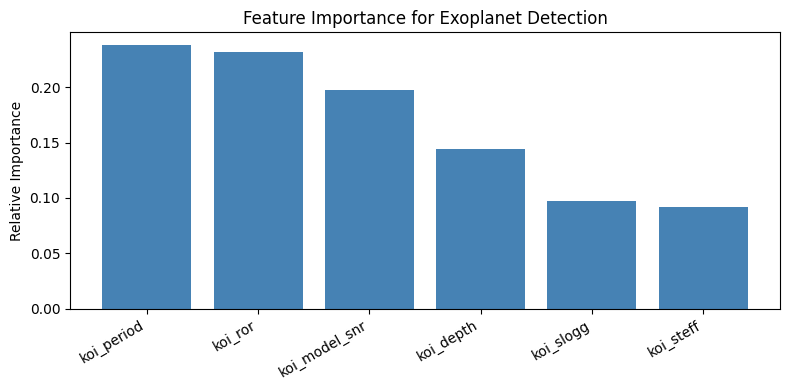

In [25]:
import matplotlib.pyplot as plt

# Extract feature importances from trained model
importances = clf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8, 4))
plt.title("Feature Importance for Exoplanet Detection")
plt.bar(range(X.shape[1]), importances[indices], color="steelblue")
plt.xticks(
    range(X.shape[1]), [features[i] for i in indices], rotation=30, ha="right"
)
plt.ylabel("Relative Importance")
plt.tight_layout()
plt.show()

In [27]:
# Create DataFrame with exact feature names matching the training set
sample_features = pd.DataFrame(
    [
        [
            best_period.value,
            transit_depth,
            radius_ratio,
            5780,
            4.4,
            40.0,
        ]
    ],
    columns=[
        "koi_period",
        "koi_depth",
        "koi_ror",
        "koi_steff",
        "koi_slogg",
        "koi_model_snr",
    ],
)

prediction = clf.predict(sample_features)